# ДЗ 04 Разведывательный анализ данных

### Импорты и чтение данных

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

DATA_PATH = Path("../data/HomeWork.csv")

df = pd.read_csv(DATA_PATH, index_col=0)
df["timestamp"] = pd.to_datetime(df["timestamp"], errors="coerce")
df.head()

,status,income,age,timestamp
0,Student,4000.0,18.0,2026-03-02
1,Student,4000.0,18.0,2026-03-25
2,Student,0.0,0.0,2026-03-29
3,Student,1000.0,20.0,2026-03-05
4,Student,2000.0,22.0,2026-03-06


### Разведочный анализ
#### Общая статистика по датасету

In [2]:
print("=" * 50 + "Статистики числовых признаков" + "=" * 50)
display(df.describe())
print("=" * 50 + "Статистики категориальных признаков" + "=" * 50)
display(df.describe(include=["str"]))

==================================================Статистики числовых признаков==================================================


,income,age,timestamp
count,823.000000,968.000000,1000
mean,136234.967193,43.541322,2026-03-15 17:29:45.600000
min,-13745.000000,0.000000,2026-03-01 00:00:00
25%,5000.000000,29.000000,2026-03-07 18:00:00
50%,96000.000000,43.000000,2026-03-16 00:00:00
75%,205500.000000,57.000000,2026-03-24 00:00:00
max,992000.000000,99.000000,2026-03-30 00:00:00
std,171113.478156,19.098784,NaN


==================================================Статистики категориальных признаков==================================================


,status
count,994
unique,4
top,Working
freq,421


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   status     994 non-null    str           
 1   income     823 non-null    float64       
 2   age        968 non-null    float64       
 3   timestamp  1000 non-null   datetime64[us]
dtypes: datetime64[us](1), float64(2), str(1)
memory usage: 31.4 KB


#### Выводы:

> В поле `income` есть некорректное отрицательное значение. Разброс больше среднего значения. Высокая вариативность. Возможно ассиметричное распределение.

> В поле `age` так же есть аномально низкие и аномально высокие значения (0 и 99). Если такие записи немногочисленны, я бы их удалила, как выбросы.

> В поле `timestamp` мы видим, что наш файл это месячный срез данных за март.

#### Построение графиков для числовых признаков

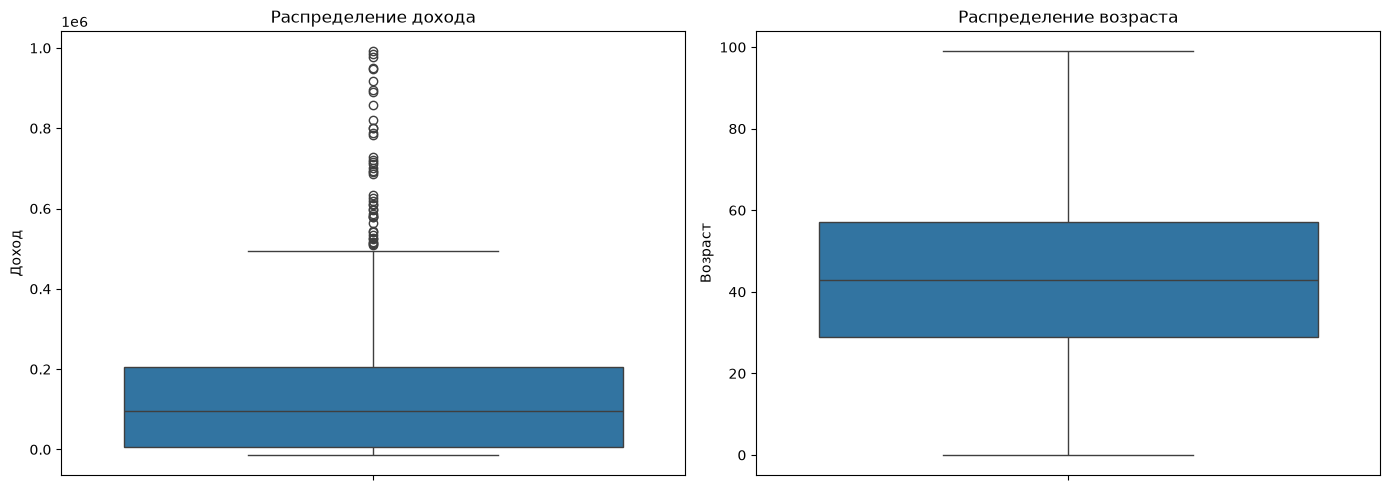

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(y=df["income"], ax=axes[0])
axes[0].set_title("Распределение дохода")
axes[0].set_ylabel("Доход")

sns.boxplot(y=df["age"], ax=axes[1])
axes[1].set_title("Распределение возраста")
axes[1].set_ylabel("Возраст")

plt.tight_layout()
plt.show()

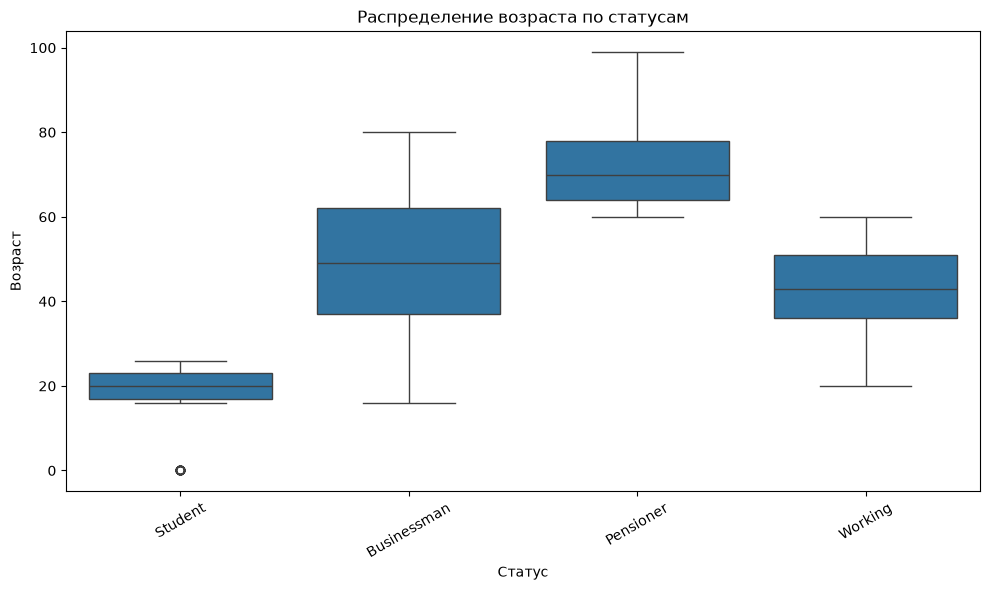

In [5]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="status",
    y="age",
)

plt.title("Распределение возраста по статусам")
plt.xlabel("Статус")
plt.ylabel("Возраст")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

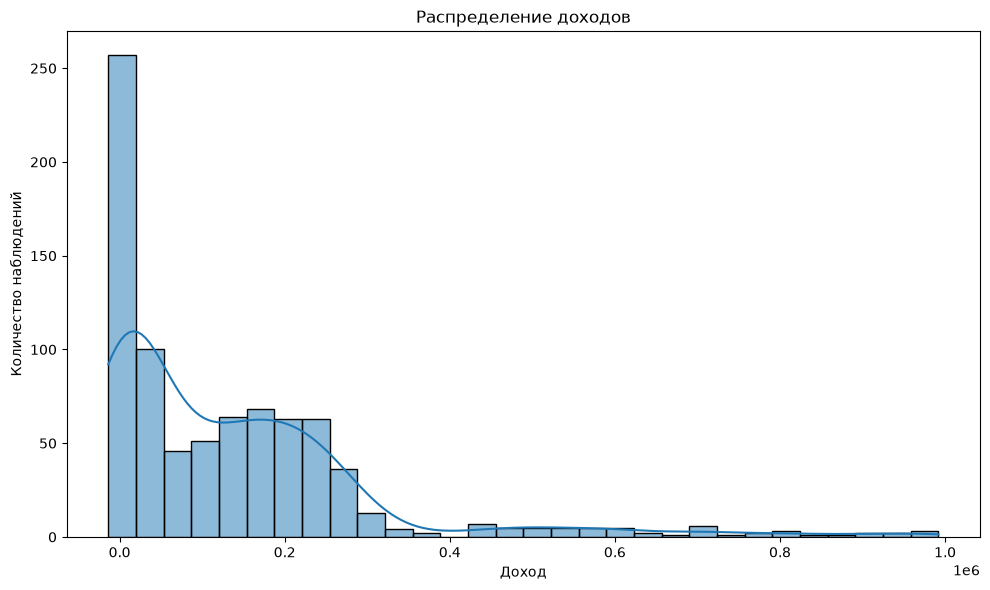

In [6]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="income",
    bins=30,
    kde=True
)

plt.title("Распределение доходов")
plt.xlabel("Доход")
plt.ylabel("Количество наблюдений")
plt.tight_layout()
plt.show()

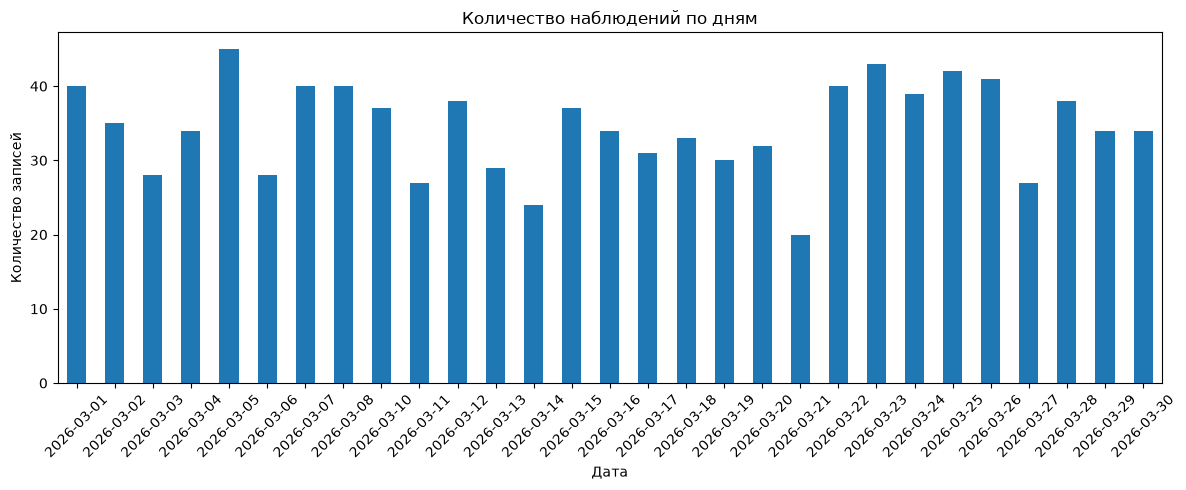

In [7]:
daily_counts = df.groupby(df["timestamp"].dt.date).size()

daily_counts.plot(kind="bar", figsize=(12, 5))

plt.title("Количество наблюдений по дням")
plt.xlabel("Дата")
plt.ylabel("Количество записей")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#### Выводы
> Общий график для возраста не выявил выбросов, однако возвраст в разрезе статусов подвтердил моё предположение, что возраст 0 это выброс.

> Для доходов видна выраженная правостороння ассиметрия. Наибольшая частота наблюдений приходится на первый бин, дальше падение в 2.5 раза. Отрицательные значения дохода так же требуют дополнительной проверки.

> На столбчатой диаграмме дат видно, что интервал между сильными провалами растягивается. В начале месяца провалы были каждые 1-2 дня, но уже после 14го числа интервал между резкими паденями увеличивается до 5-6 дней.

#### Анализ пропусков

In [8]:
missing = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2),
})

display(missing.sort_values("missing_percent", ascending=False))

,missing_count,missing_percent
income,177,17.7
age,32,3.2
status,6,0.6
timestamp,0,0.0


#### Выводы

Пропуски в большинстве колонок невелики, однако в `income` почти 18%. При этом `income` имеет очень сильный разброс в данных и выраженную правостороннюю ассиметрию. Необходимо обдумать стратегия обработки пропусков, чтобы не смазать исходную картину.

#### Анализ аномалий

In [9]:
income_negative_pct = df["income"].lt(0).mean() * 100
age_under_18_pct = df["age"].lt(18).mean() * 100
age_zero_pct = df["age"].eq(0).mean() * 100
age_over_90_pct = df["age"].gt(90).mean() * 100

print(f"Доля отрицательных доходов: {income_negative_pct:.2f}%")
print(f"Доля клиентов младше 18 лет: {age_under_18_pct:.2f}%")
print(f"Доля клиентов 0 лет: {age_zero_pct:.2f}%")
print(f"Доля клиентов старше 90 лет: {age_over_90_pct:.2f}%")
print("Возраст от 1 до 17 лет:", df["age"].between(1, 17).sum())

Доля отрицательных доходов: 4.60%
Доля клиентов младше 18 лет: 5.80%
Доля клиентов 0 лет: 2.90%
Доля клиентов старше 90 лет: 0.90%
Возраст от 1 до 17 лет: 29


In [10]:
df.loc[df["age"].between(0, 17), "age"].value_counts().sort_index()

age
0.0     29
16.0    15
17.0    14
Name: count, dtype: int64

#### Выводы

Возраст старше 90 лет встречается очень редко, что ожидаемо, половина из клиентов младше 18 имеют возраст 0 лет, что выглядит как некорректное значение.

### Обработка пропусков и выбросов

Возраст 0 лет заменяем пропуском. Пропуски заполняем медианой, так как данных очень мало и лучше лишние строки не удалять. Медиана выбрана здесь и далее,так как устойчива к выбросам и не требует нормального распределения.

Так как дополнительной информации по датасету и предметной обаласти нет, то несовершеннолетних клиентов и аномально старых оставляем.

In [11]:
df_clean = df.copy()

In [12]:
df_clean.loc[df_clean["age"] == 0, "age"] = pd.NA
df_clean["age"] = df_clean["age"].fillna(df_clean["age"].median())
print(f"Количество пропусков после обработки: {df_clean["age"].isna().sum()}")
print("Возраст 0 лет после обработки:", df_clean["age"].eq(0).sum())

Количество пропусков после обработки: 0
Возраст 0 лет после обработки: 0


Для поля `status` добавляем новую категорию `Unknown` для заполнения пропусков.

In [13]:
df_clean["status"] = df_clean["status"].fillna("Unknown")
print("Пропуски в status после обработки:", df_clean["status"].isna().sum())
print("\nРаспределение статусов после обработки:")
print(df_clean["status"].value_counts(dropna=False))

Пропуски в status после обработки: 0

Распределение статусов после обработки:
status
Working        421
Businessman    274
Student        173
Pensioner      126
Unknown          6
Name: count, dtype: int64


#### Обработка поля income

Обрезка выбросов

In [14]:
q1 = df_clean["income"].quantile(0.25)
q3 = df_clean["income"].quantile(0.75)
iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

below = df_clean["income"] < lower_bound
above = df_clean["income"] > upper_bound

outliers_before = (below | above).sum()

print(f"Нижняя граница IQR: {lower_bound:.2f}")
print("Ниже нижней границы:", below.sum())
print(f"Верхняя граница IQR: {upper_bound:.2f}")
print("Выше верхней границы:", above.sum())
print(f"Потенциальных выбросов до обработки: {outliers_before}")

df_clean["income"] = df_clean["income"].clip(
    lower=lower_bound,
    upper=upper_bound,
)

Нижняя граница IQR: -295750.00
Ниже нижней границы: 0
Верхняя граница IQR: 506250.00
Выше верхней границы: 43
Потенциальных выбросов до обработки: 43


Заполнение пропусков

In [15]:
df_clean["income"] = df_clean["income"].fillna(
    df_clean["income"].median()
)

Сначала обрезаны выбросы, чтобы заполнением пропусков не сместить границы по IQR

### Итоговый вывод

В ходе обработки данных пропуски в `income` и `age` заполнены медианой, а пропуски в `status` — отдельной категорией `Unknown`. Нулевой возраст интерпретирован как некорректное значение и заменён на пропуск с последующим заполнением медианой. Потенциальные выбросы в `income` выявлены методом IQR: 43 значения выше верхней границы ограничены её значением. Отрицательные доходы, несовершеннолетние клиенты и возраст старше 90 лет сохранены, поскольку без дополнительной информации нельзя однозначно признать их ошибочными. В результате выбранная обработка позволяет сохранить все наблюдения, уменьшить влияние экстремальных доходов и устранить пропуски, не делая необоснованных предположений о данных.

### Сравнение данных до и после обработки

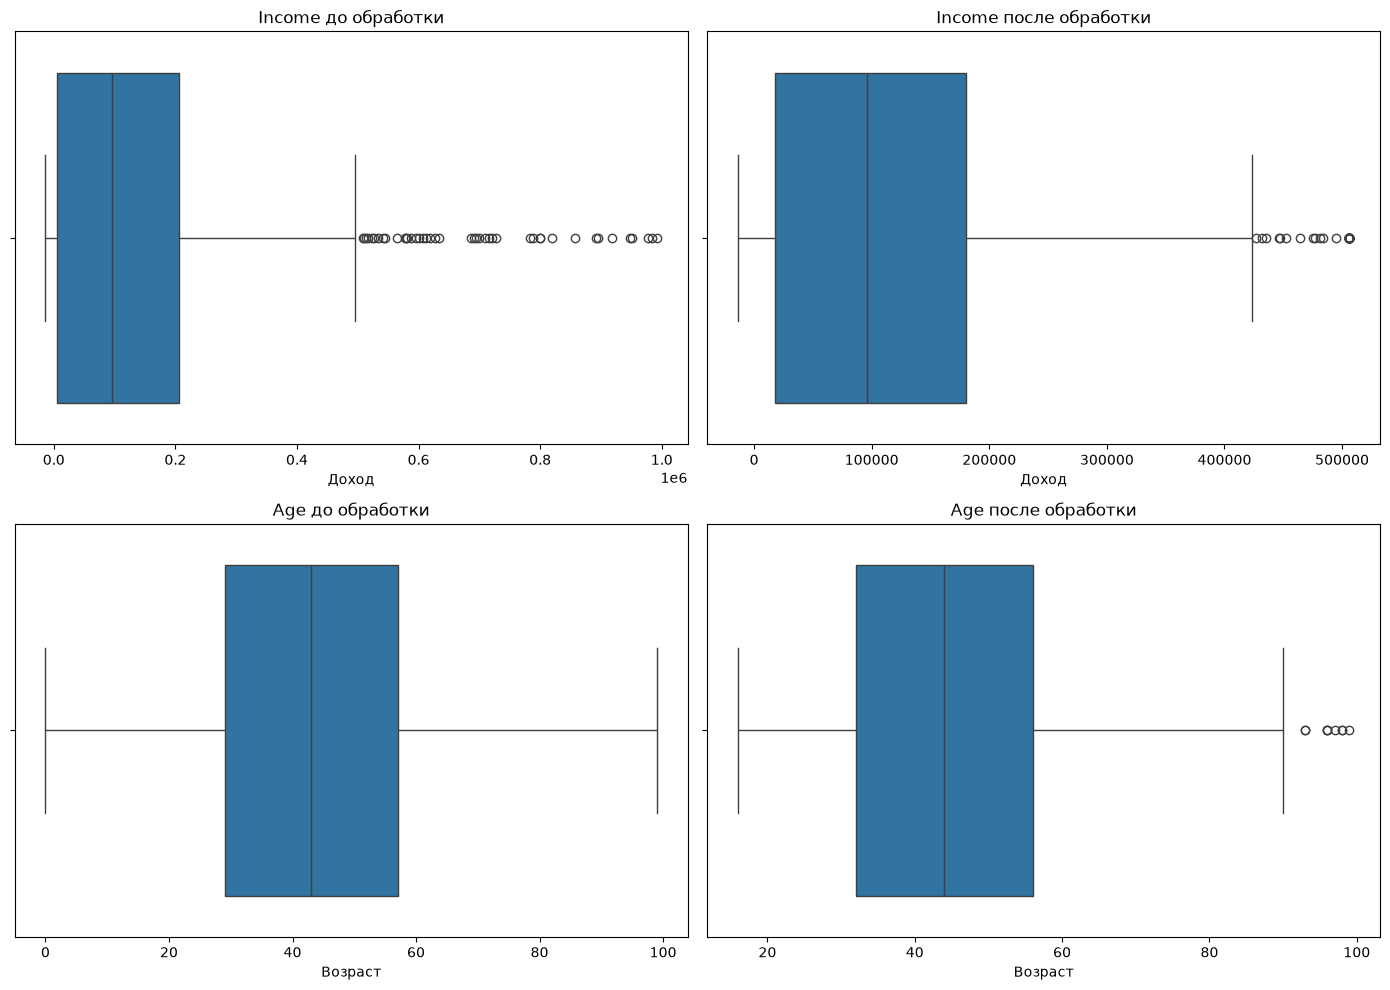

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.boxplot(data=df, x="income", ax=axes[0, 0])
axes[0, 0].set_title("Income до обработки")
axes[0, 0].set_xlabel("Доход")

sns.boxplot(data=df_clean, x="income", ax=axes[0, 1])
axes[0, 1].set_title("Income после обработки")
axes[0, 1].set_xlabel("Доход")


sns.boxplot(data=df, x="age", ax=axes[1, 0])
axes[1, 0].set_title("Age до обработки")
axes[1, 0].set_xlabel("Возраст")

sns.boxplot(data=df_clean, x="age", ax=axes[1, 1])
axes[1, 1].set_title("Age после обработки")
axes[1, 1].set_xlabel("Возраст")

plt.tight_layout()
plt.show()

После обработки `income` правый хвост распределения стал короче, поскольку 43 значения выше верхней границы IQR были ограничены. Для `age` после обработки стали заметнее потенциальные выбросы среди клиентов старше 90 лет. Визуальная разница может быть связана с изменением квартилей после замены нулевого возраста на пропуски и заполнения пропусков медианой. Поскольку дополнительной информации о клиентах нет, значения возраста старше 90 лет сохранены.

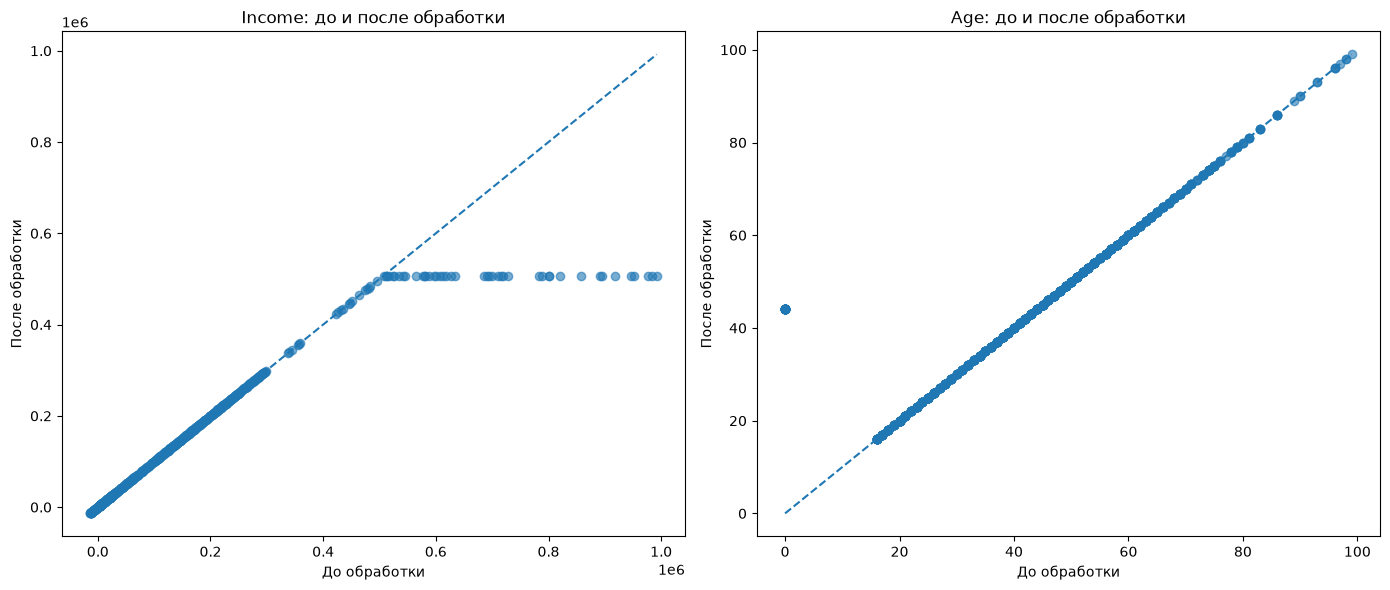

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].scatter(
    df["income"],
    df_clean["income"],
    alpha=0.6,
)
axes[0].set_title("Income: до и после обработки")
axes[0].set_xlabel("До обработки")
axes[0].set_ylabel("После обработки")

income_min = min(
    df["income"].min(),
    df_clean["income"].min(),
)
income_max = max(
    df["income"].max(),
    df_clean["income"].max(),
)
axes[0].plot(
    [income_min, income_max],
    [income_min, income_max],
    linestyle="--",
)

axes[1].scatter(
    df["age"],
    df_clean["age"],
    alpha=0.6,
)
axes[1].set_title("Age: до и после обработки")
axes[1].set_xlabel("До обработки")
axes[1].set_ylabel("После обработки")

age_min = min(df["age"].min(), df_clean["age"].min())
age_max = max(df["age"].max(), df_clean["age"].max())
axes[1].plot(
    [age_min, age_max],
    [age_min, age_max],
    linestyle="--",
)

plt.tight_layout()
plt.show()

На графике `income` горизонтальная линия отражает наблюдения, для которых значения после обработки стали одинаковыми. В частности, это могут быть доходы, ограниченные верхней границей IQR.

На графике для `age` мы можем видеть как 0 возраст превратился в медианный 43.

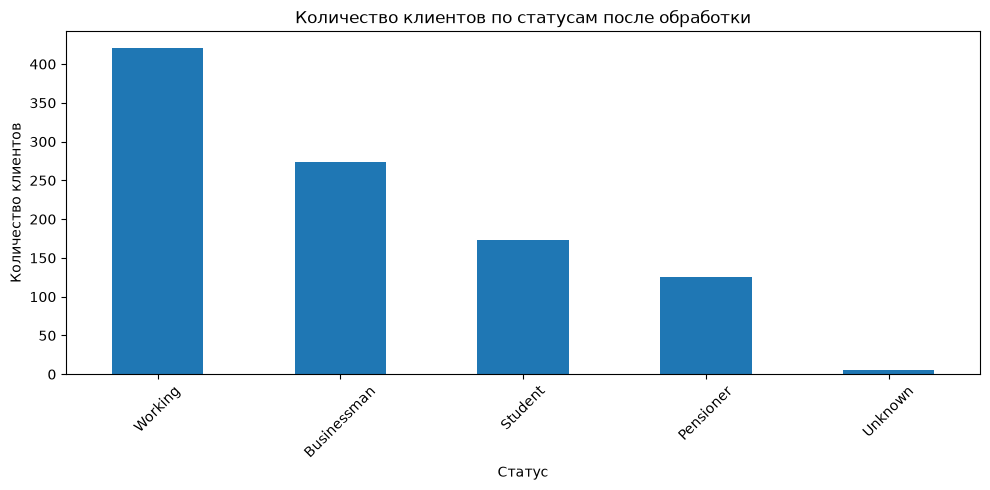

In [18]:
status_counts = df_clean["status"].value_counts()

status_counts.plot(kind="bar", figsize=(10, 5))

plt.title("Количество клиентов по статусам после обработки")
plt.xlabel("Статус")
plt.ylabel("Количество клиентов")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [19]:
unknown_count = (df_clean["status"] == "Unknown").sum()
unknown_share = unknown_count / len(df_clean) * 100

print(f"Клиентов с неизвестным статусом: {unknown_count}")
print(f"Доля клиентов с неизвестным статусом: {unknown_share:.2f}%")

Клиентов с неизвестным статусом: 6
Доля клиентов с неизвестным статусом: 0.60%


Доля клиентов в новой категории невелика, поэтому её добавление практически не влияет на общее распределение статусов.